# Bearing Fault Detection from Motor Current (MCSA) — Exploration

**Dataset:** Paderborn bearing dataset (6203 bearings); vibration + motor current, 4 s @ 64 kHz.

**Goal:** decide, from data, whether the **current signal alone** can separate **healthy** from **damaged** bearings.


## 1 · Setup

In [1]:
# Imports: all exploration helpers live in src/utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import (
    build_metadata,           # corpus metadata table
    parse_filename,           # filename grammar decoder
    audit_data_folder,        # grid check: present vs expected files
    get_label,                # healthy / damaged
    load_recording,           # .mat loader -> per-channel arrays
    inspect_recordings,       # schema + stats per channel
    scan_signal_sanity,       # NaN / inf / flat / range per recording
    scan_corpus,
    summarize_anomalies,      # corpus-level anomaly report
    build_bearings_table,     # damage taxonomy
    time_domain_features,
    build_feature_table,      # time-domain feature extraction
    fault_frequencies,        # BPFO / BPFI / BSF / FTF
    psd,
    envelope_spectrum,        # frequency-domain helpers
    fault_band_ratio,
    RATE_VIB, RATE_CUR, LINE_FREQ,
    assign_folds,             # evaluation splits (bearings-wise)
    assignment_b,
    verify,
    CHANNEL_CATALOG,
)

## 2 · Corpus inventory

In [4]:
# Build
metadata = build_metadata(refresh=True)
display(metadata.head())

,bearing,speed_rpm,torque_Nm,force_N,rep,filepath,label
0,K001,900,0.7,1000,1,/home/marwaneze/Projects/Personal/Motor_PM/dat...,healthy
1,K001,900,0.7,1000,10,/home/marwaneze/Projects/Personal/Motor_PM/dat...,healthy
2,K001,900,0.7,1000,11,/home/marwaneze/Projects/Personal/Motor_PM/dat...,healthy
3,K001,900,0.7,1000,12,/home/marwaneze/Projects/Personal/Motor_PM/dat...,healthy
4,K001,900,0.7,1000,13,/home/marwaneze/Projects/Personal/Motor_PM/dat...,healthy


In [3]:
# Corpus summary: bearings, class balance, operating points
print("bearings:", sorted(metadata["bearing"].unique()))
print(metadata["label"].value_counts().to_string())
print("\nBearings per class:")
print(metadata.groupby("label")["bearing"].nunique().to_string())
print("\nOperating conditions:")
display(metadata[["speed_rpm", "torque_Nm", "force_N"]].drop_duplicates())

bearings: ['K001', 'K002', 'K003', 'K004', 'K005', 'K006', 'KA01', 'KA03', 'KA04', 'KA05', 'KA06', 'KA07', 'KA08', 'KA09', 'KA15', 'KA16', 'KA22', 'KA30', 'KB23', 'KB24', 'KB27', 'KI01', 'KI03', 'KI04', 'KI05', 'KI07', 'KI08', 'KI14', 'KI16', 'KI17', 'KI18', 'KI21']
label
damaged    2077
healthy     480

Bearings per class:
label
damaged    26
healthy     6

Operating conditions:


,speed_rpm,torque_Nm,force_N
0,900,0.7,1000
20,1500,0.1,1000
40,1500,0.7,400
60,1500,0.7,1000


## 3 · Filename grammar

In [4]:
# Decode file names into (speed, torque, force, bearing, rep)
for stem in ["N15_M07_F10_K001_3", "N09_M07_F10_KA01_11",
             "N15_M01_F10_KI21_20", "N15_M07_F04_KB23_1"]:
    print(f"{stem:20s} -> {parse_filename(stem)}")

N15_M07_F10_K001_3   -> {'bearing': 'K001', 'speed_rpm': 1500, 'torque_Nm': 0.7, 'force_N': 1000, 'rep': 3}
N09_M07_F10_KA01_11  -> {'bearing': 'KA01', 'speed_rpm': 900, 'torque_Nm': 0.7, 'force_N': 1000, 'rep': 11}
N15_M01_F10_KI21_20  -> {'bearing': 'KI21', 'speed_rpm': 1500, 'torque_Nm': 0.1, 'force_N': 1000, 'rep': 20}
N15_M07_F04_KB23_1   -> {'bearing': 'KB23', 'speed_rpm': 1500, 'torque_Nm': 0.7, 'force_N': 400, 'rep': 1}


## 4 · Signal schema & channel catalog

In [5]:
# Expected channels: sample rate / length / role / unit
display(pd.DataFrame(CHANNEL_CATALOG).T)

,rate,samples,role,unit
vibration_1,64000,256001,fault_primary,g
phase_current_1,64000,256001,fault_secondary,A
phase_current_2,64000,256001,fault_secondary,A
speed,4000,16001,condition,rpm
torque,4000,16001,condition,Nm
force,4000,16001,condition,N
temp_2_bearing_module,1,5,condition,degC


In [6]:
# Validate one healthy recording against the catalog
path = metadata[(metadata["bearing"] == "K001") & (metadata["rep"] == 1)]["filepath"].iloc[0]
report = inspect_recordings(path)
display(pd.DataFrame(report).T)

,shape,dtype,samples,min,max,expected_samples,matches_catalog
force,"(16008,)",float64,16008,791.45957,1291.337499,16001,False
phase_current_1,"(256823,)",float64,256823,-2.853623,2.877041,256001,False
phase_current_2,"(256823,)",float64,256823,-2.769591,2.750305,256001,False
speed,"(16008,)",float64,16008,899.413253,900.140777,16001,False
temp_2_bearing_module,"(5,)",float64,5,46.710205,47.009277,5,True
torque,"(16008,)",float64,16008,1.002617,1.471853,16001,False
vibration_1,"(256823,)",float64,256823,-4.879761,4.690552,256001,False


In [7]:
# Recording lengths vary
sizes = {}
for b in ["K001", "K003", "KA03", "KI21"]:
    rec = metadata[(metadata["bearing"] == b) & (metadata["rep"] == 1)].iloc[0]
    sizes[b] = load_recording(rec["filepath"])["vibration_1"].size
print("vibration_1 samples:", sizes)

vibration_1 samples: {'K001': 256823, 'K003': 256000, 'KA03': 256001, 'KI21': 256003}


## 5 · Data integrity

In [8]:
# Corpus grid audit: present vs expected files
audit = audit_data_folder(verify_loads=False)
print(f"present {audit['present_files']} / expected {audit['expected_files']}")
print("missing:", audit["missing"] or "none")
print("load failures:", audit["load_failures"] or "none")

[audit] MISSING 3 expected recordings
present 2557 / expected 2560
missing: [('KA05', 'N15_M07_F10', 16), ('KA08', 'N15_M01_F10', 2), ('KA08', 'N15_M07_F10', 11)]
load failures: none


In [9]:
# Per-recording sanity: one healthy, one artificial, one real-damage file
paths = [
    metadata[(metadata["bearing"] == "K001") & (metadata["rep"] == 1)]["filepath"].iloc[0],
    metadata[(metadata["bearing"] == "KA01") & (metadata["rep"] == 1)]["filepath"].iloc[0],
    metadata[(metadata["bearing"] == "KI01") & (metadata["rep"] == 1)]["filepath"].iloc[0],
]
for p in paths:
    print("\n== ", p.split("/")[-1])
    display(pd.DataFrame(scan_signal_sanity(p)).T[["samples", "nan", "inf", "flat", "min", "max", "within_limits"]])


==  N09_M07_F10_K001_1.mat


,samples,nan,inf,flat,min,max,within_limits
force,16008,0,0,False,791.45957,1291.337499,True
phase_current_1,256823,0,0,False,-2.853623,2.877041,True
phase_current_2,256823,0,0,False,-2.769591,2.750305,True
speed,16008,0,0,False,899.413253,900.140777,True
temp_2_bearing_module,5,0,0,False,46.710205,47.009277,True
torque,16008,0,0,False,1.002617,1.471853,True
vibration_1,256823,0,0,False,-4.879761,4.690552,True



==  N09_M07_F10_KA01_1.mat


,samples,nan,inf,flat,min,max,within_limits
force,16001,0,0,False,868.058691,1228.471288,True
phase_current_1,256001,0,0,False,-3.003088,2.928011,True
phase_current_2,256001,0,0,False,-3.015486,2.706912,True
speed,16001,0,0,False,898.78652,900.742217,True
temp_2_bearing_module,5,0,0,False,46.115112,46.472168,True
torque,16001,0,0,False,1.122331,1.374956,True
vibration_1,256001,0,0,False,-2.145386,2.404785,True



==  N09_M07_F10_KI01_1.mat


,samples,nan,inf,flat,min,max,within_limits
force,16001,0,0,False,725.846777,1263.871679,True
phase_current_1,256001,0,0,False,-2.869465,2.742729,True
phase_current_2,256001,0,0,False,-2.957629,2.706912,True
speed,16001,0,0,False,898.502173,901.39363,True
temp_2_bearing_module,5,0,0,False,47.164917,47.402954,True
torque,16001,0,0,False,0.976775,1.418786,True
vibration_1,256001,0,0,False,-4.977417,5.633545,True


In [10]:
# Corpus-level anomaly scan (50-file sample)
scan = scan_corpus(max_files=50)
display(summarize_anomalies(scan))


,files,nan_files,inf_files,flat_files,out_of_limits,min_value,max_value
channel,,,,,,,
force,50,0,0,0,0,129.228125,1370.378026
phase_current_1,50,0,0,0,0,-3.057502,3.094696
phase_current_2,50,0,0,0,0,-3.044415,3.105717
speed,50,0,0,0,0,898.914224,1500.463161
temp_2_bearing_module,50,0,0,0,0,44.140625,47.009277
torque,50,0,0,0,0,0.389224,1.512252
vibration_1,50,0,0,0,0,-5.419922,5.184937


In [11]:
# Full-corpus anomaly scan (~minutes, run once) + persist report
full_scan = scan_corpus()
display(summarize_anomalies(full_scan))
full_scan.to_csv("../data/processed/anomaly_report.csv", index=False)


  scanned 400/2557
  scanned 800/2557
  scanned 1200/2557
  scanned 1600/2557
  scanned 2000/2557
  scanned 2400/2557


,files,nan_files,inf_files,flat_files,out_of_limits,min_value,max_value
channel,,,,,,,
force,2557,0,0,0,1,-0.471582,1561.418065
phase_current_1,2557,0,0,0,0,-3.260004,3.144977
phase_current_2,2557,0,0,0,0,-3.765570,4.377897
speed,2557,0,0,0,0,679.619290,1516.690914
temp_2_bearing_module,2557,0,0,0,1,-1.147461,78.372192
torque,2557,0,0,0,1,-0.191534,1.578656
vibration_1,2557,0,0,0,11,-9.573364,10.928345


## 6 · Damage taxonomy

In [12]:
# Bearing -> damage type: healthy / artificial / real / combination
bearings_table = build_bearings_table(metadata)
display(bearings_table.groupby("damage_type").agg(
    bearings=("bearing", "count"), recordings=("n_recordings", "sum")))

saved: /home/marwaneze/Projects/Personal/Motor_PM/data/processed/bearings.csv


,bearings,recordings
damage_type,,
artificial,12,957
combination,3,240
healthy,6,480
real,11,880


## 7 · Time-domain features

In [13]:
# Single-file stats: one healthy vs one real damage vs one artificial-damage recording
for b in ["K001","KI01", "KA01"]:
    path = metadata[(metadata["bearing"] == b) & metadata["filepath"].str.contains("N15_M07_F10")]["filepath"].iloc[0]
    feat = time_domain_features(load_recording(path)["vibration_1"])
    print(f"{b:5s} vibration_1:", {k: round(v, 3) for k, v in feat.items()})

K001  vibration_1: {'rms': 0.407, 'mean': -0.019, 'std': 0.406, 'peak': 4.929, 'peak_to_peak': 9.32, 'crest_factor': 12.12, 'skewness': 0.026, 'kurtosis': 10.101}
KI01  vibration_1: {'rms': 0.687, 'mean': -0.019, 'std': 0.687, 'peak': 8.206, 'peak_to_peak': 15.872, 'crest_factor': 11.945, 'skewness': 0.347, 'kurtosis': 11.763}
KA01  vibration_1: {'rms': 0.539, 'mean': -0.017, 'std': 0.539, 'peak': 4.12, 'peak_to_peak': 7.883, 'crest_factor': 7.643, 'skewness': 0.699, 'kurtosis': 11.581}


In [14]:
# Per-recording feature table over a representative bearing sample
feats = build_feature_table(metadata, bearings=["K003", "KA05", "KB23", "KI21"], reps=[1, 2, 3])
print("rows:", len(feats))
display(feats.drop(columns=["bearing", "condition", "rep"]).head(20))

rows: 48


,label,vibration_1_samples,vibration_1_rms,vibration_1_mean,vibration_1_std,vibration_1_peak,vibration_1_peak_to_peak,vibration_1_crest_factor,vibration_1_skewness,vibration_1_kurtosis,...,phase_current_1_kurtosis,phase_current_2_samples,phase_current_2_rms,phase_current_2_mean,phase_current_2_std,phase_current_2_peak,phase_current_2_peak_to_peak,phase_current_2_crest_factor,phase_current_2_skewness,phase_current_2_kurtosis
0,healthy,256000,0.338158,-0.011922,0.337948,4.391479,8.389282,12.986478,0.025503,17.817845,...,-1.494603,256000,1.640629,-0.010275,1.640597,2.762704,5.381452,1.683929,0.001824,-1.494017
1,healthy,256001,0.334387,-0.012996,0.334135,4.476929,8.850098,13.388458,0.074609,17.641239,...,-1.494036,256001,1.664512,-0.006621,1.664499,2.942476,5.605995,1.767771,0.001555,-1.494271
2,healthy,256084,0.330621,-0.012938,0.330368,5.001831,9.362793,15.128591,0.135705,18.150463,...,-1.494024,256084,1.670245,-0.011328,1.670206,2.972093,5.665230,1.779436,0.000975,-1.494219
3,healthy,262593,0.363024,-0.013968,0.362755,4.083252,8.114624,11.247893,0.039489,12.937929,...,-1.485524,262593,0.933681,0.001467,0.933680,1.778434,3.443909,1.904755,0.014873,-1.488173
4,healthy,258898,0.357625,-0.013476,0.357371,5.340576,9.289551,14.933444,0.098126,13.220988,...,-1.483819,258898,0.919902,-0.003123,0.919897,1.836981,3.463195,1.996930,-0.005895,-1.488213
5,healthy,256001,0.369285,-0.013755,0.369029,4.571533,8.737183,12.379420,-0.026544,12.817924,...,-1.490493,256001,0.916301,-0.001921,0.916299,1.969916,3.685671,2.149857,0.006762,-1.485146
6,healthy,256001,0.371557,-0.013541,0.371310,4.391479,8.740234,11.819135,0.109203,13.397264,...,-1.496473,256001,1.782951,-0.002968,1.782949,3.037527,5.860155,1.703652,-0.000224,-1.494925
7,healthy,260053,0.362575,-0.015453,0.362246,4.959106,9.448242,13.677454,-0.017217,13.171443,...,-1.499426,260053,1.773345,0.004398,1.773340,2.955562,5.740996,1.666659,0.005815,-1.496146
8,healthy,256001,0.358394,-0.013669,0.358133,4.385376,8.761597,12.236194,0.153368,13.494876,...,-1.501626,256001,1.770229,-0.012942,1.770182,2.956251,5.731353,1.669982,-0.004821,-1.494933
9,healthy,256000,0.364916,-0.013959,0.364649,5.044556,9.475708,13.823888,-0.018389,13.492668,...,-1.503635,256000,1.759298,-0.004502,1.759292,3.060257,5.853267,1.739476,0.007486,-1.492993


In [15]:
# Class separation: mean / std per feature across labels
key_cols = [c for c in feats.columns if c.startswith("vibration_1_")]
display(feats.groupby("label")[key_cols].agg(["mean", "std"]).T.round(3))

label                             damaged     healthy
vibration_1_samples      mean  257505.500  257136.167
                         std     6019.229    2191.086
vibration_1_rms          mean       0.333       0.356
                         std        0.162       0.014
vibration_1_mean         mean       0.004      -0.014
                         std        0.028       0.001
vibration_1_std          mean       0.331       0.356
                         std        0.163       0.014
vibration_1_peak         mean       3.210       4.637
                         std        1.464       0.366
vibration_1_peak_to_peak mean       6.029       8.915
                         std        2.730       0.429
vibration_1_crest_factor mean      10.209      13.040
                         std        3.539       1.198
vibration_1_skewness     mean       0.045       0.052
                         std        0.087       0.062
vibration_1_kurtosis     mean       4.998      14.480
                         std        5.807       2.086

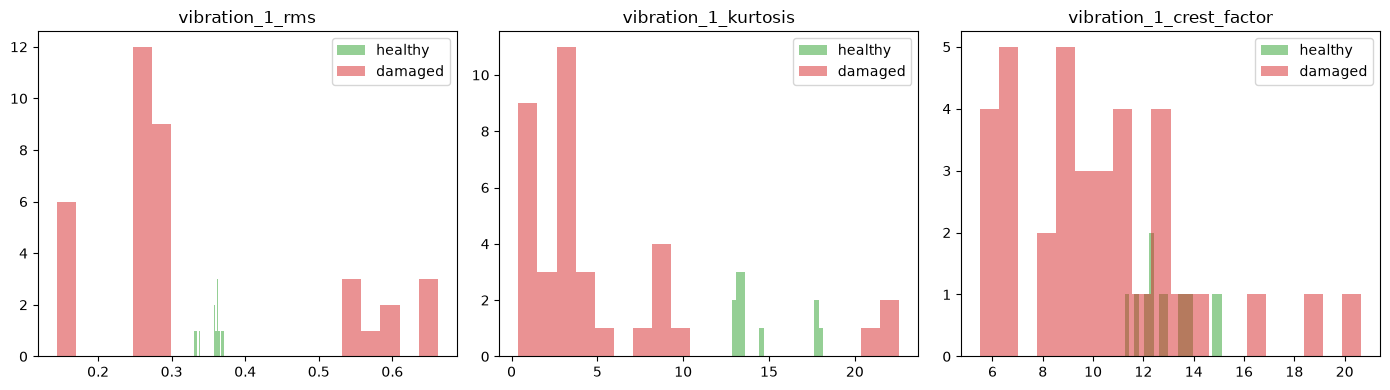

In [16]:
# Visual: healthy vs damaged overlap of the key features
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["vibration_1_rms", "vibration_1_kurtosis", "vibration_1_crest_factor"]):
    for label, color in zip(["healthy", "damaged"], ["tab:green", "tab:red"]):
        ax.hist(feats[feats["label"] == label][col].dropna(), bins=20, alpha=0.5, label=label, color=color)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

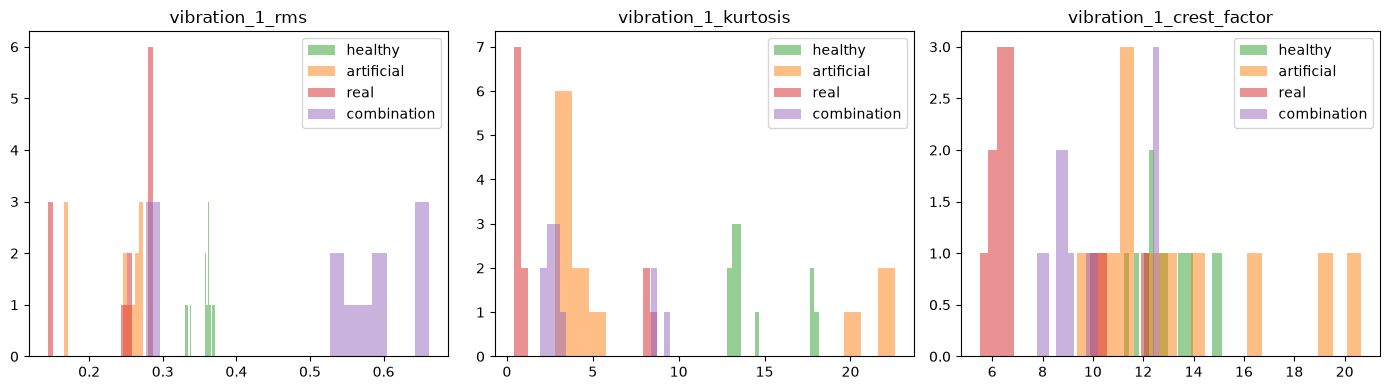

In [17]:
damage_map = build_bearings_table(metadata, save=False).set_index("bearing")["damage_type"].to_dict()
feats["subtype"] = feats["bearing"].map(damage_map)
subtypes = [("healthy", "tab:green"), ("artificial", "tab:orange"),
            ("real", "tab:red"), ("combination", "tab:purple")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["vibration_1_rms", "vibration_1_kurtosis", "vibration_1_crest_factor"]):
    for name, color in subtypes:
        ax.hist(feats[feats["subtype"] == name][col].dropna(), bins=20, alpha=0.5,
                label=name, color=color)
    ax.set_title(col)
    ax.legend()
plt.tight_layout(); plt.show()

## 8 · Frequency domain & MCSA

In [18]:
# Characteristic fault frequencies at both shaft speeds
for hz in (25.0, 15.0):
    print(f"at {hz * 60:.0f} rpm:", {k: round(v, 1) for k, v in fault_frequencies(hz).items()})

at 1500 rpm: {'shaft': 25.0, 'ftf': np.float64(9.5), 'bpfo': np.float64(76.3), 'bpfi': np.float64(123.7), 'bsf': np.float64(49.8)}
at 900 rpm: {'shaft': 15.0, 'ftf': np.float64(5.7), 'bpfo': np.float64(45.8), 'bpfi': np.float64(74.2), 'bsf': np.float64(29.9)}


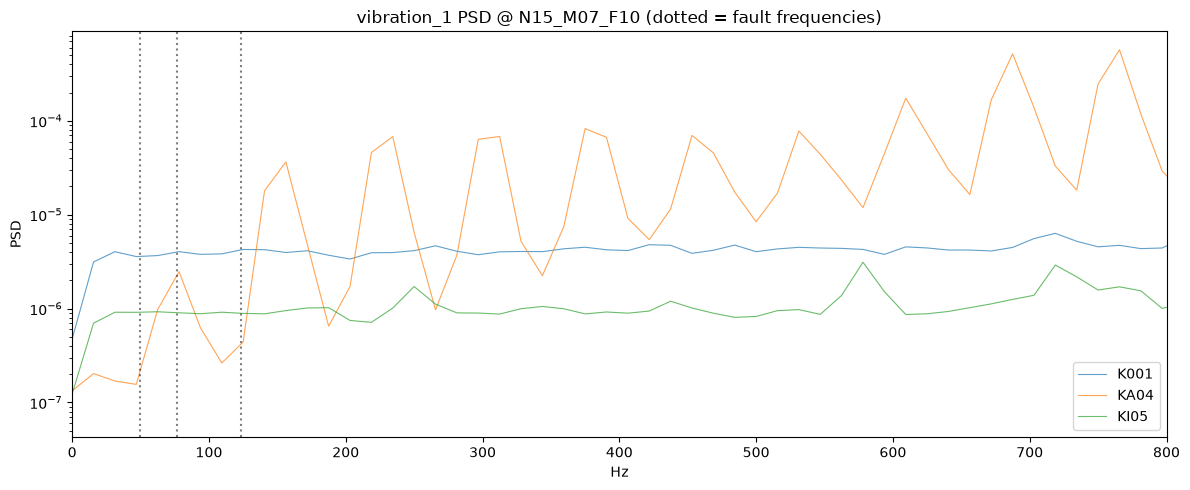

In [19]:
# Vibration PSD: healthy vs damaged at the same operating point (N15_M07_F10)
fig, ax = plt.subplots(figsize=(12, 5))
for b in ["K001", "KA04", "KI05"]:
    path = metadata[(metadata["bearing"] == b) & metadata["filepath"].str.contains("N15_M07_F10")]["filepath"].iloc[0]
    f, p = psd(load_recording(path)["vibration_1"], RATE_VIB)
    ax.semilogy(f, p, lw=0.8, alpha=0.7, label=f"{b}")
ff = fault_frequencies(25.0)
for name in ["bpfo", "bpfi", "bsf"]:
    ax.axvline(ff[name], ls=":", color="k", alpha=0.5)
ax.set_xlim(0, 800); ax.set_xlabel("Hz"); ax.set_ylabel("PSD"); ax.legend()
ax.set_title("vibration_1 PSD @ N15_M07_F10 (dotted = fault frequencies)")
plt.tight_layout(); plt.show()

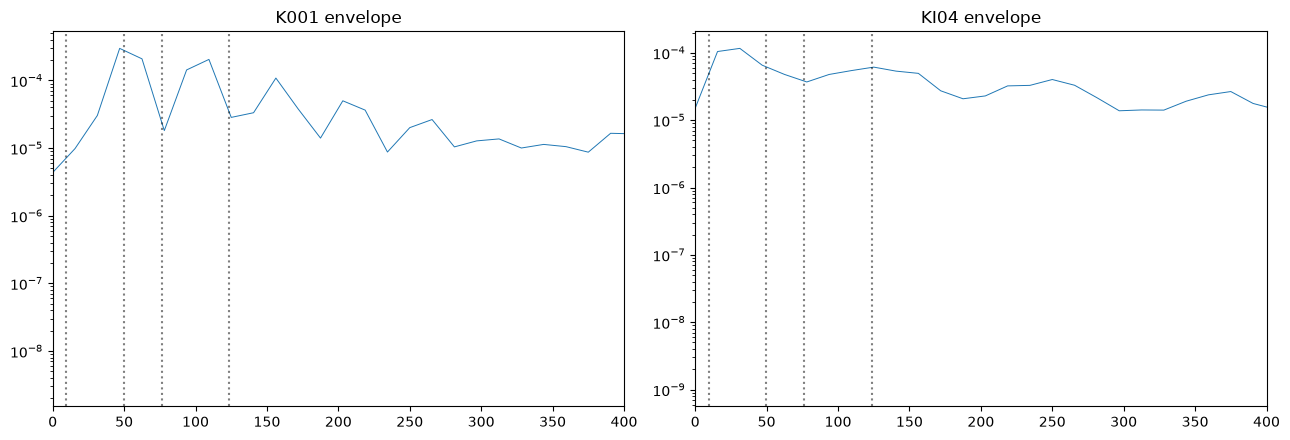

In [20]:
# Envelope spectrum (band-pass + Hilbert): impulse content healthy vs damaged
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, b in zip(axes, ["K001", "KI04"]):
    path = metadata[(metadata["bearing"] == b) & metadata["filepath"].str.contains("N15_M07_F10")]["filepath"].iloc[0]
    f, p = envelope_spectrum(load_recording(path)["vibration_1"], RATE_VIB)
    ax.semilogy(f, p, lw=0.7)
    for name in ["ftf", "bsf", "bpfo", "bpfi"]:
        ax.axvline(fault_frequencies(25.0)[name], ls=":", color="k", alpha=0.5)
    ax.set_xlim(0, 400); ax.set_title(f"{b} envelope")
plt.tight_layout(); plt.show()

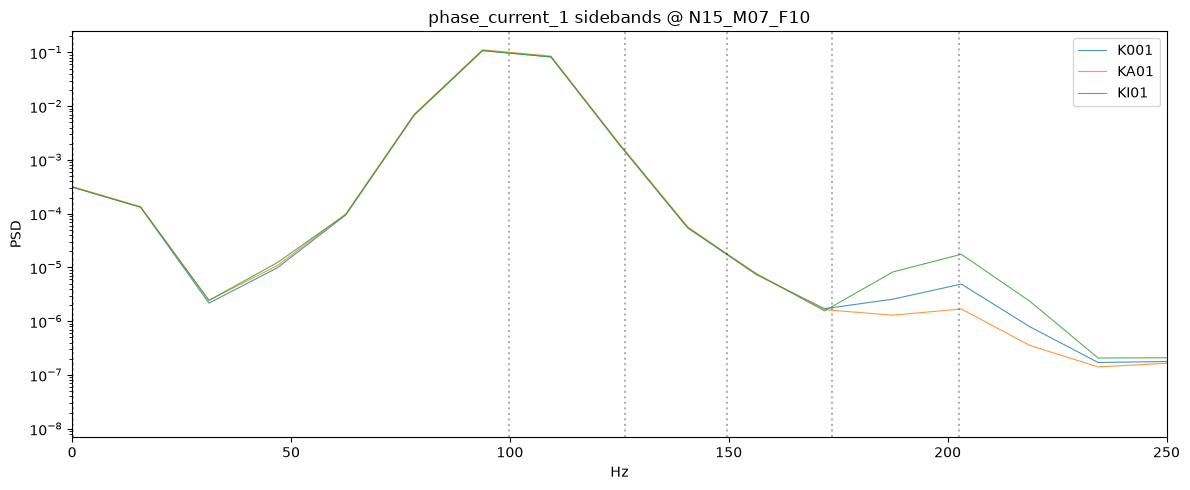

In [21]:
# MCSA: current sidebands around 50 Hz (signature = 50 +/- k * fault freq)
fig, ax = plt.subplots(figsize=(12, 5))
for b in ["K001", "KA01",'KI01']:
    path = metadata[(metadata["bearing"] == b) & metadata["filepath"].str.contains("N15_M07_F10")]["filepath"].iloc[0]
    f, p = psd(load_recording(path)["phase_current_1"], RATE_CUR)
    ax.semilogy(f, p, lw=0.8, alpha=0.8, label=f"{b}")
ff = fault_frequencies(25.0)
for name in ["bpfo", "bpfi", "bsf"]:
    for k in [1, 2]:
        for sign in [-1, 1]:
            ax.axvline(LINE_FREQ + sign * k * ff[name], ls=":", color="k", alpha=0.3)
ax.set_xlim(0, 250); ax.set_xlabel("Hz"); ax.set_ylabel("PSD"); ax.legend()
ax.set_title("phase_current_1 sidebands @ N15_M07_F10")
plt.tight_layout(); plt.show()

In [22]:
# Bearing-level verdict: BPFO band ratio, vibration vs current
rows = []
for b in sorted(metadata[metadata["filepath"].str.contains("N15_M07_F10")]["bearing"].unique()):
    sub = metadata[(metadata["bearing"] == b) & metadata["filepath"].str.contains("N15_M07_F10")]
    sub = sub[sub["rep"] <= 3]
    vib, cur = [], []
    for _, rec in sub.iterrows():
        s = load_recording(rec["filepath"])
        f, p = psd(s["vibration_1"], RATE_VIB)
        vib.append(fault_band_ratio(f, p, fault_frequencies(25.0)["bpfo"]))
        f, p = psd(s["phase_current_1"], RATE_CUR)
        cur.append(fault_band_ratio(f, p, fault_frequencies(25.0)["bpfo"]))
    rows.append({"bearing": b, "label": get_label(b),
                 "vib_bpfo_ratio": float(np.mean(vib)),
                 "cur_bpfo_ratio": float(np.mean(cur))})
bp = pd.DataFrame(rows).sort_values("vib_bpfo_ratio", ascending=False)
display(bp.round(2))

,bearing,label,vib_bpfo_ratio,cur_bpfo_ratio
24,KI05,damaged,1.02,59697.89
2,K003,healthy,0.96,66462.20
5,K006,healthy,0.91,46452.26
0,K001,healthy,0.89,56546.06
4,K005,healthy,0.88,105303.64
9,KA05,damaged,0.87,67682.60
26,KI08,damaged,0.86,56620.08
1,K002,healthy,0.85,64718.29
25,KI07,damaged,0.83,60449.77
11,KA07,damaged,0.82,69262.76


## 9 · Evaluation split design

In [5]:
# Split A: stratified bearing-wise 5-fold CV (tune the model here)
splits_a = assign_folds(metadata, n_folds=5, seed=42)
verify(metadata, splits_a, "A")
display(splits_a.groupby(["fold", "label"]).agg(
    bearings=("bearing", "nunique"), recordings=("filepath", "count")))


verify OK: A


bearings  recordings
fold label                        
0    damaged         6         478
     healthy         2         160
1    damaged         5         400
     healthy         1          80
2    damaged         5         399
     healthy         1          80
3    damaged         5         400
     healthy         1          80
4    damaged         5         400
     healthy         1          80

In [24]:
# Split B: train = artificial + healthy, test = real/combination (deployment verdict)
splits_b = assignment_b(metadata)
verify(metadata, splits_b, "B")
display(splits_b.groupby(["partition", "label"]).agg(
    bearings=("bearing", "nunique"), recordings=("filepath", "count")))

verify OK: B


bearings  recordings
partition label                        
test      damaged        14        1120
train     damaged        12         957
          healthy         6         480

In [25]:
# Leakage + balance summary; majority-class baseline
print("Split A bearings per fold:", splits_a.groupby("fold")["bearing"].nunique().to_dict())
print("Split B test bearings:", sorted(splits_b[splits_b.partition == "test"]["bearing"].unique()))
print("Split B majority baseline (all-damaged) train:",
      round((splits_b[splits_b.partition == "train"].label == "damaged").mean(), 3))

Split A bearings per fold: {0: 8, 1: 6, 2: 6, 3: 6, 4: 6}
Split B test bearings: ['KB23', 'KB24', 'KB27', 'KI01', 'KI03', 'KI04', 'KI05', 'KI07', 'KI08', 'KI14', 'KI16', 'KI17', 'KI18', 'KI21']
Split B majority baseline (all-damaged) train: 0.666
